# Hierarchical Clustering

## 1. What is Hierarchical Clustering?

Hierarchical Clustering is an unsupervised machine learning algorithm that groups similar data points into clusters by building a hierarchy of clusters.

Unlike K-Means, it does not require us to specify the number of clusters before building the hierarchy.

## 2. Types of Hierarchical Clustering

- **Agglomerative (Bottom-Up):** Starts with each data point as a separate cluster and repeatedly merges the closest clusters.
- **Divisive (Top-Down):** Starts with all data points in one cluster and repeatedly splits them into smaller clusters.

Agglomerative clustering is the commonly used approach.

## 3. How Does Agglomerative Clustering Work?

1. Treat every data point as an individual cluster.
2. Calculate the distances between clusters.
3. Merge the two closest clusters based on the selected linkage method.
4. Recalculate distances between the updated clusters.
5. Repeat until all points belong to one cluster or the required number of clusters is reached.

## 4. Linkage Methods

Linkage determines how the distance between two clusters is calculated.

- **Single Linkage:** Uses the minimum pairwise distance between two clusters. Can produce chain-like clusters.
- **Complete Linkage:** Uses the maximum pairwise distance between two clusters. Generally favors compact clusters.
- **Average Linkage:** Uses the average of all pairwise distances between two clusters.
- **Ward Linkage:** Merges clusters that produce the smallest increase in within-cluster sum of squared distances. Commonly produces compact clusters and uses Euclidean distance.

## 5. Dendrogram

A dendrogram is a tree-like diagram that shows the order in which clusters merge and the distance at which each merge occurs.

- The leaves represent individual data points.
- The branches represent cluster merges.
- The height of a merge represents its linkage distance or merge criterion.

We can draw a horizontal cut across the dendrogram to obtain a chosen number of clusters.

## 6. Choosing the Number of Clusters

The number of clusters can be selected by:
- Examining the dendrogram for large vertical gaps between merge heights.
- Comparing Silhouette Scores for different cluster counts.
- Considering the problem's requirements.

## 7. Implementation Using Scikit-learn

```python
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

labels = model.fit_predict(X_scaled)
```

- `n_clusters=3`: Produces three clusters.
- `linkage="ward"`: Uses Ward's merging criterion.
- `fit_predict()`: Fits the clustering model and returns a cluster label for each data point.

Feature scaling is important when features have different units or scales.

## 8. Advantages and Limitations

**Advantages**
- Does not require specifying the number of clusters to build the full hierarchy.
- Dendrograms help visualize relationships between clusters.
- Supports different linkage methods.

**Limitations**
- Can be computationally expensive for large datasets.
- Early merge decisions are generally not reversed.
- Results can vary depending on the linkage method and distance metric.

## 9. Key Takeaway

Hierarchical Clustering builds a hierarchy of clusters by repeatedly merging or splitting groups. Linkage determines how cluster distances are measured, and a dendrogram helps us decide where to cut the hierarchy to obtain the desired clusters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

In [2]:
X, _ = make_blobs(
    n_samples=10,
    centers=3,
    n_features=2,
    cluster_std=1.2,
    random_state=42
)

print("Dataset shape:", X.shape)
print(X)

Dataset shape: (10, 2)
[[-5.12084867 -7.15104115]
 [-7.53288646 -6.74700249]
 [ 3.42448149  2.35026648]
 [-6.79859335 -8.58980742]
 [-2.2188429   6.71834983]
 [-3.07256689  9.66535818]
 [-0.61414224  9.9352078 ]
 [ 2.56997744  1.29842465]
 [ 3.55024995  0.27840524]
 [-3.06529885  8.45541042]]


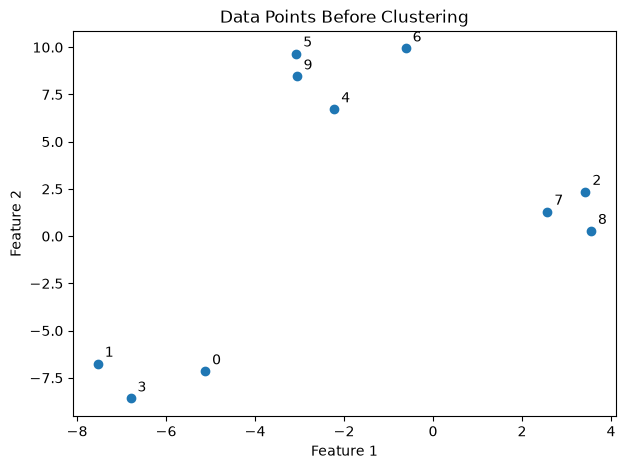

In [3]:
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 1])

for i, point in enumerate(X):
    plt.annotate(
        str(i),
        (point[0], point[1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Data Points Before Clustering")
plt.show()

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
from scipy.cluster.hierarchy import linkage, dendrogram

In [6]:
linkage_matrix = linkage(
    X_scaled,
    method="ward"
)

print(linkage_matrix)

[[ 5.          9.          0.17836805  2.        ]
 [ 2.          7.          0.27050114  2.        ]
 [ 8.         11.          0.3109344   3.        ]
 [ 1.          3.          0.33177004  2.        ]
 [ 4.         10.          0.47302335  3.        ]
 [ 0.         13.          0.61878706  3.        ]
 [ 6.         14.          0.75180626  4.        ]
 [12.         16.          3.29397417  7.        ]
 [15.         17.          5.25986078 10.        ]]


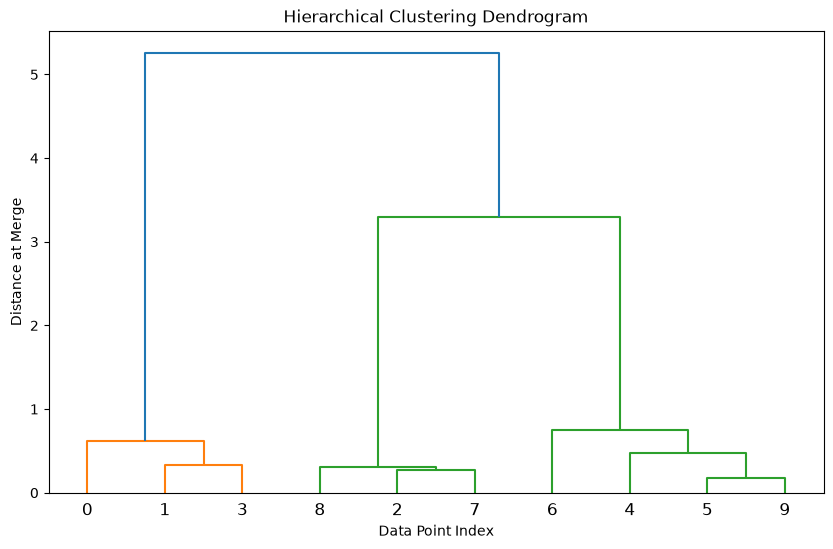

In [8]:
plt.figure(figsize=(10, 6))

dendrogram(
    linkage_matrix,
    labels=[str(i) for i in range(len(X_scaled))]
)

plt.xlabel("Data Point Index")
plt.ylabel("Distance at Merge")
plt.title("Hierarchical Clustering Dendrogram")

plt.show()